# Polars Fundamentals

**Polars** is a DataFrame library written in Rust on top of Apache Arrow. It uses all CPU cores, has a consistent **expression** API, and a query optimiser. For many workloads it is several times faster than pandas and uses less memory.

**After this lesson you can:**

1. Read data and inspect a Polars DataFrame.
2. Write **expressions** with `pl.col` and use them in `select`, `with_columns`, `filter`.
3. Group, aggregate, join and use window functions (`over`).
4. Translate common pandas code to Polars and compare the speed.

**Data:** NYC yellow taxi trips, January 2024, and the taxi zone lookup table.

In [1]:
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path.cwd().parent / "tools"))
import datasets                                   # course helper: downloads pinned public datasets

import polars as pl

JAN, FEB = datasets.taxi("2024-01"), datasets.taxi("2024-02")
zones_pl = pl.read_csv(datasets.fetch("taxi_zone_lookup.csv"))

def show_plan(text: str) -> None:
    """Print a query plan without the local folder of the data files."""
    print(text.replace(str(JAN.parent) + "/", "").replace(str(JAN.parent), ""))

print("Polars", pl.__version__)

trips = pl.read_parquet(JAN)
print(trips.shape)
trips.head(3)

Polars 2.1.0


(2964624, 19)


VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee
i32,datetime[μs],datetime[μs],i64,f64,i64,str,i32,i32,i64,f64,f64,f64,f64,f64,f64,f64,f64,f64
2,2024-01-01 00:57:55,2024-01-01 01:17:43,1,1.72,1,"""N""",186,79,2,17.7,1.0,0.5,0.0,0.0,1.0,22.7,2.5,0.0
1,2024-01-01 00:03:00,2024-01-01 00:09:36,1,1.8,1,"""N""",140,236,1,10.0,3.5,0.5,3.75,0.0,1.0,18.75,2.5,0.0
1,2024-01-01 00:17:06,2024-01-01 00:35:01,1,4.7,1,"""N""",236,79,1,23.3,3.5,0.5,3.0,0.0,1.0,31.3,2.5,0.0


## 1. Key Differences from pandas

| | pandas | Polars |
| :--- | :--- | :--- |
| row labels | index | **no index**; rows are positions |
| style | many methods, some in place | **expressions**, always return new frames |
| execution | single-threaded (mostly) | **multi-threaded** |
| modes | eager | eager (`read_*`) and **lazy** (`scan_*`, Lesson 17) |
| memory format | NumPy / Arrow | Arrow |
| missing values | `NaN`, `None`, `pd.NA` | `null` (and `NaN` only as a float value) |

## 2. Expressions

An **expression** describes a computation on columns: `pl.col("fare_amount") * 1.1`. It does nothing until a **context** runs it:

- `select(...)`: return only the given expressions,
- `with_columns(...)`: add or replace columns,
- `filter(...)`: keep rows where the expression is true,
- `group_by(...).agg(...)`: one row per group.

Polars runs the expressions of one context **in parallel**.

In [2]:
duration = (pl.col("tpep_dropoff_datetime") - pl.col("tpep_pickup_datetime")).dt.total_seconds() / 60
clean = (
    trips
    .with_columns(duration_min=duration)
    .filter(
        pl.col("tpep_pickup_datetime").is_between(pl.datetime(2024, 1, 1), pl.datetime(2024, 2, 1), closed="left"),
        pl.col("duration_min").is_between(1, 180),
        pl.col("trip_distance").is_between(0.1, 100),
        pl.col("fare_amount").is_between(3, 500),
        pl.col("total_amount") > 0,
    )
    .with_columns(
        speed_mph=pl.col("trip_distance") / (pl.col("duration_min") / 60),
        tip_pct=100 * pl.col("tip_amount") / pl.col("fare_amount"),
        hour=pl.col("tpep_pickup_datetime").dt.hour(),
        weekday=pl.col("tpep_pickup_datetime").dt.weekday(),          # 1 = Monday ... 7 = Sunday
    )
)
print(f"{trips.height:,} -> {clean.height:,} clean trips (the same rules as pandas Lesson 08)")
clean.select("trip_distance", "duration_min", "speed_mph", "tip_pct").describe()

2,964,624 -> 2,855,769 clean trips (the same rules as pandas Lesson 08)


statistic,trip_distance,duration_min,speed_mph,tip_pct
str,f64,f64,f64,f64
"""count""",2.855769e6,2.855769e6,2.855769e6,2.855769e6
"""null_count""",0.0,0.0,0.0,0.0
"""mean""",3.301648,15.005314,11.525159,20.801596
"""std""",4.372402,11.795785,7.086681,15.495276
"""min""",0.1,1.0,0.046059,0.0
"""25%""",1.03,7.316667,7.402894,9.345794
"""50%""",1.7,11.75,9.675626,24.411765
"""75%""",3.2,18.783333,13.123746,29.62963
"""max""",97.5,179.066667,1835.0,2348.837209


Several conditions in one `filter` are combined with "and". Expressions can be reused: `duration` is a Python variable that holds an expression.

## 3. Selecting Columns

`pl.col` accepts names, lists, regular expressions and data types; the `polars.selectors` module adds readable helpers.

In [3]:
import polars.selectors as cs

print(clean.select(pl.col("^.*_amount$")).columns)
print(clean.select(cs.datetime()).columns)
print(clean.select(cs.numeric() - cs.integer()).columns[:6])
print(clean.select(pl.all().exclude("^tpep.*$")).width, "columns without the timestamps")

['fare_amount', 'tip_amount', 'tolls_amount', 'total_amount']
['tpep_pickup_datetime', 'tpep_dropoff_datetime']
['trip_distance', 'fare_amount', 'extra', 'mta_tax', 'tip_amount', 'tolls_amount']
22 columns without the timestamps


## 4. Group, Aggregate, Join

In [4]:
by_zone = (
    clean.group_by("PULocationID")
    .agg(trips=pl.len(), median_fare=pl.col("fare_amount").median(), mean_tip_pct=pl.col("tip_pct").mean(),
         revenue=pl.col("total_amount").sum())
    .join(zones_pl, left_on="PULocationID", right_on="LocationID", how="left")
    .sort("trips", descending=True)
)
by_zone.select("Zone", "Borough", "trips", "median_fare", "mean_tip_pct").head(6)

Zone,Borough,trips,median_fare,mean_tip_pct
str,str,u32,f64,f64
"""Upper East Side South""","""Manhattan""",139737,10.0,22.826776
"""Midtown Center""","""Manhattan""",139665,12.1,21.660261
"""JFK Airport""","""Queens""",136851,70.0,14.202601
"""Upper East Side North""","""Manhattan""",133515,10.7,22.58869
"""Midtown East""","""Manhattan""",104035,12.1,21.935171
"""Times Sq/Theatre District""","""Manhattan""",102457,12.8,20.65893


## 5. Window Functions with `over`

`expr.over("key")` computes the expression **per group** and returns one value per row, like `transform` in pandas or a SQL window function (M07 L07).

shape: (4, 5)
┌──────────────┬─────────────┬─────────────┬──────────────┬───────────────┐
│ PULocationID ┆ fare_amount ┆ zone_median ┆ rank_in_zone ┆ share_of_hour │
│ ---          ┆ ---         ┆ ---         ┆ ---          ┆ ---           │
│ i32          ┆ f64         ┆ f64         ┆ u32          ┆ f64           │
╞══════════════╪═════════════╪═════════════╪══════════════╪═══════════════╡
│ 186          ┆ 17.7        ┆ 13.5        ┆ 29090        ┆ 0.026157      │
│ 140          ┆ 10.0        ┆ 12.1        ┆ 40005        ┆ 0.026157      │
│ 236          ┆ 23.3        ┆ 10.7        ┆ 10857        ┆ 0.026157      │
│ 79           ┆ 10.0        ┆ 12.1        ┆ 39252        ┆ 0.026157      │
└──────────────┴─────────────┴─────────────┴──────────────┴───────────────┘


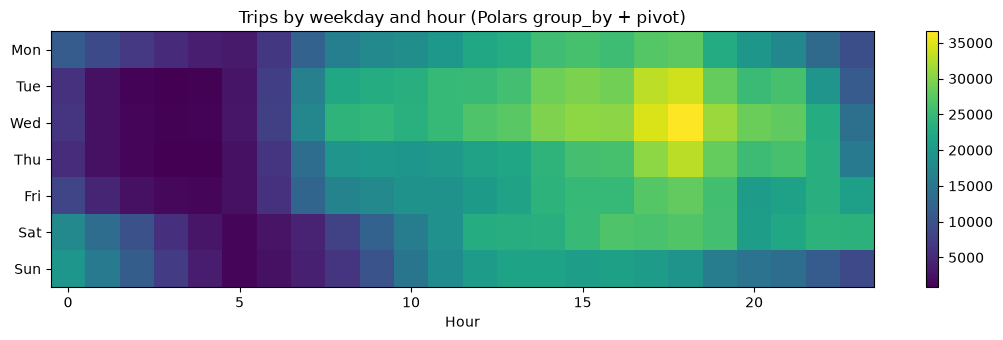

In [5]:
ranked = clean.with_columns(
    zone_median=pl.col("fare_amount").median().over("PULocationID"),
    rank_in_zone=pl.col("fare_amount").rank("ordinal", descending=True).over("PULocationID"),
    share_of_hour=pl.len().over("hour") / pl.len(),
)
print(ranked.select("PULocationID", "fare_amount", "zone_median", "rank_in_zone", "share_of_hour").head(4))
heat = clean.group_by("weekday", "hour").agg(pl.len()).pivot(on="hour", index="weekday", values="len").sort("weekday")
heat_np = heat.select(sorted([c for c in heat.columns if c != "weekday"], key=int)).to_numpy()

fig, ax = plt.subplots(figsize=(11, 3.5))
im = ax.imshow(heat_np, aspect="auto", cmap="viridis")
ax.set(yticks=range(7), yticklabels=["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"], xlabel="Hour",
       title="Trips by weekday and hour (Polars group_by + pivot)")
fig.colorbar(im, ax=ax)
plt.tight_layout()
plt.show()

## 6. pandas vs Polars: the Same Pipeline

The benchmark runs the same pipeline in both libraries: filter, derive two columns, group by pickup zone and hour, aggregate three measures.

In [6]:
pdf = trips.to_pandas()

def pandas_pipeline(df):
    d = (df["tpep_dropoff_datetime"] - df["tpep_pickup_datetime"]).dt.total_seconds() / 60
    m = d.between(1, 180) & df["fare_amount"].between(3, 500) & df["trip_distance"].between(0.1, 100)
    out = df[m].assign(duration_min=d[m], hour=df.loc[m, "tpep_pickup_datetime"].dt.hour,
                       tip_pct=100 * df.loc[m, "tip_amount"] / df.loc[m, "fare_amount"])
    return out.groupby(["PULocationID", "hour"]).agg(trips=("fare_amount", "size"), fare=("fare_amount", "mean"),
                                                    tip=("tip_pct", "median"))

def polars_pipeline(df):
    return (df.with_columns(duration_min=duration)
              .filter(pl.col("duration_min").is_between(1, 180), pl.col("fare_amount").is_between(3, 500),
                      pl.col("trip_distance").is_between(0.1, 100))
              .with_columns(hour=pl.col("tpep_pickup_datetime").dt.hour(), tip_pct=100 * pl.col("tip_amount") / pl.col("fare_amount"))
              .group_by("PULocationID", "hour")
              .agg(trips=pl.len(), fare=pl.col("fare_amount").mean(), tip=pl.col("tip_pct").median()))

def best(fn, arg, n=3):
    times = []
    for _ in range(n):
        t = time.perf_counter(); r = fn(arg); times.append(time.perf_counter() - t)
    return min(times), r

t_pd, r_pd = best(pandas_pipeline, pdf)
t_pl, r_pl = best(polars_pipeline, trips)
print(f"pandas {t_pd * 1000:.0f} ms | Polars {t_pl * 1000:.0f} ms -> {t_pd / t_pl:.1f}x faster | groups: {len(r_pd):,} vs {r_pl.height:,}")
check = r_pl.sort("PULocationID", "hour").to_pandas().set_index(["PULocationID", "hour"])
print("same fare means:", np.allclose(check["fare"].to_numpy(), r_pd.sort_index()["fare"].to_numpy()))

pandas 533 ms | Polars 218 ms -> 2.4x faster | groups: 5,092 vs 5,092
same fare means: True


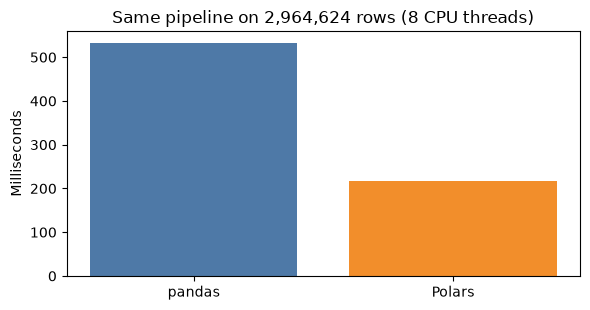

In [7]:
import os

fig, ax = plt.subplots(figsize=(6, 3.2))
ax.bar(["pandas", "Polars"], [t_pd * 1000, t_pl * 1000], color=["#4E79A7", "#F28E2B"])
ax.set(title=f"Same pipeline on {trips.height:,} rows ({os.cpu_count()} CPU threads)", ylabel="Milliseconds")
plt.tight_layout()
plt.show()

## 7. Translation Table

| pandas | Polars |
| :--- | :--- |
| `df["a"]`, `df[["a", "b"]]` | `df["a"]`, `df.select("a", "b")` |
| `df[df["a"] > 1]` | `df.filter(pl.col("a") > 1)` |
| `df.assign(c=df["a"] * 2)` | `df.with_columns(c=pl.col("a") * 2)` |
| `df.groupby("k").agg(n=("a", "size"))` | `df.group_by("k").agg(n=pl.len())` |
| `df.groupby("k")["a"].transform("mean")` | `pl.col("a").mean().over("k")` |
| `df.merge(o, on="k", how="left")` | `df.join(o, on="k", how="left")` |
| `df.sort_values("a", ascending=False)` | `df.sort("a", descending=True)` |
| `np.where(c, x, y)` | `pl.when(c).then(x).otherwise(y)` |

*Insight: Think in expressions: describe each column as a computation on other columns, and let Polars run them in parallel. Convert to pandas at the edges (plots, libraries that need pandas) via Arrow, which costs little.*

## Real-World Use Case or Analogy

pandas is like **one very experienced cook** who prepares dishes one after another. Polars is like a **kitchen brigade with a head chef**: you hand in the whole order (expressions), the head chef plans it and the cooks work in parallel.

Many data teams now use Polars for medium-sized data (millions to a few billion rows on one machine), for example for feature pipelines and ETL jobs, while keeping pandas where libraries require it.